# Homework 4

Autor: Hubert Kozierkiewicz

## Dataset

Recznie pobrane i rozpakowane w data/

In [16]:
import pandas as pd

IMAGES_DIR = "data/abo-images-small/images/small"
METADATA = "data/abo-images-small/images/metadata/images.csv.gz"
OUT = "data/abo-images-small/image_paths.txt"

df = pd.read_csv(METADATA)
print(f"wszystkie: {len(df)}")

df = df[(df["width"] >= 1000) & (df["height"] >= 1000)]
print(f"min 1000x1000: {len(df)}")

# path w csv jest wzgledny do images/small
paths = IMAGES_DIR + "/" + df["path"]

with open(OUT, "w") as f:
    f.write("\n".join(paths))


wszystkie: 398212
min 1000x1000: 342878


In [17]:
with open("data/abo-images-small/image_paths.txt") as f:
    image_paths = f.read().splitlines()

len(image_paths), image_paths[:3]

(342878,
 ['data/abo-images-small/images/small/46/4689906d.png',
  'data/abo-images-small/images/small/0c/0cd7596c.jpg',
  'data/abo-images-small/images/small/e6/e602a9af.jpg'])

## Model

Model clip-ViT-B-32 z sentence-transformers z d = 512

## Baza

Biorę tę samą z pierwszej częsci laba

In [18]:
from typing import List, Optional

import numpy as np
from pgvector.sqlalchemy import Vector
from sqlalchemy import Boolean, Engine, Float, Integer, String, Text, create_engine, select
from sqlalchemy.engine import URL
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)

class Base(DeclarativeBase):
    __abstract__ = True

class Img(Base):
    __tablename__ = "images"
    __table_args__ = {'extend_existing': True}
    
    VECTOR_LENGTH: int = 512
    
    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[List[float]] = mapped_column(Vector(VECTOR_LENGTH))
    
# Create table
engine = create_engine(db_url)
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)


## Wektoryzacja obrazów

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device


In [20]:
import joblib
from PIL import Image
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from itertools import batched

MAX_IMAGES = 10000
BATCH_SIZE = 64 # mam gpu, wiec wiecej niz cpu_count

def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()

def vectorize_images(engine, model, image_paths):    
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):  # finish (suggestion - use `batched`)
            images = [Image.open(path) for path in images_paths_batch]
        
            # calculate embeddings
            embeddings = model.encode(images)
        
            # create Img instances for all images in batch
            imgs = [Img(image_path=path, embedding=emb) for path, emb in zip(images_paths_batch, embeddings)]
        
            # insert all batch images
            insert_images(engine, imgs)

            # update pbar
            pbar.update(len(imgs))

model = SentenceTransformer("clip-ViT-B-32", device=device)

vectorize_images(engine, model, image_paths)


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


  0%|          | 0/10000 [00:00<?, ?it/s]

## Wyszukiwanie

In [24]:
import matplotlib.pyplot as plt

class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model
        
    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        # display images
        self.display_images(found_images, k)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description) # calculate embedding of image_description
        
        # remember about session and commit
        with Session(self.engine) as session:
            query = select(Img.image_path).order_by(Img.embedding.cosine_distance(image_embedding)).limit(k)
            result = result = session.execute(query).scalars().all() # execute query
        return result
    
    def display_images(self, images, k: int):
        fig, axes = plt.subplots(1, k, figsize=(15, 5))
        
        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i+1}")
        
        plt.show()

search = ImageSearch(engine, model)


## Testy

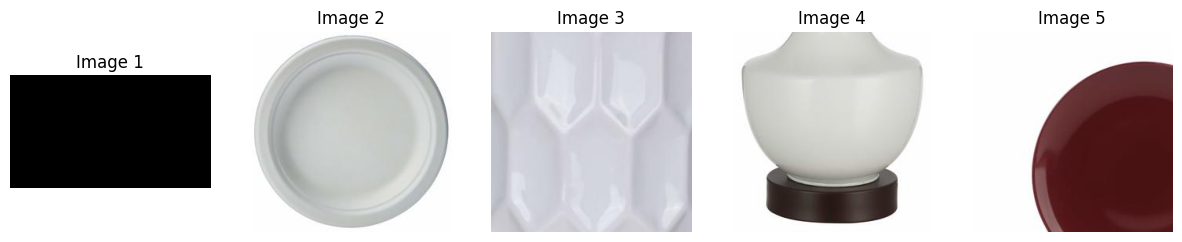

In [30]:
search("china", k=5)

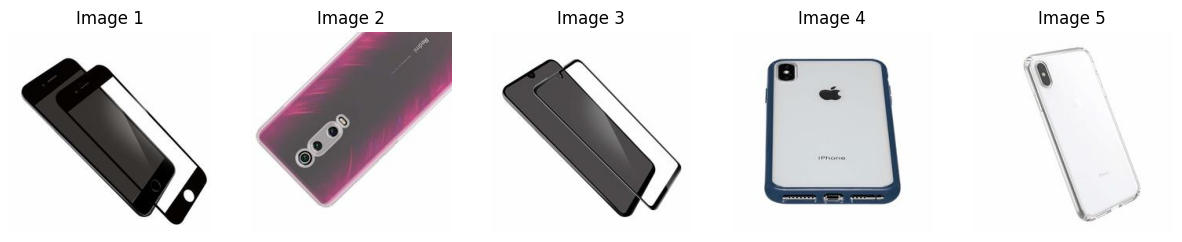

In [33]:
search("phone", k=5)

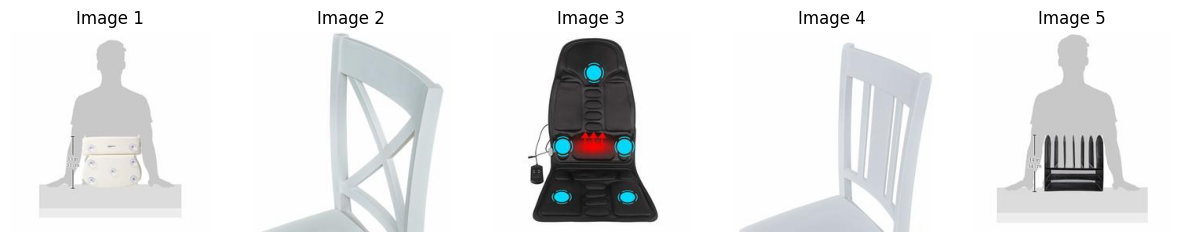

In [34]:
search("throne", k=5)

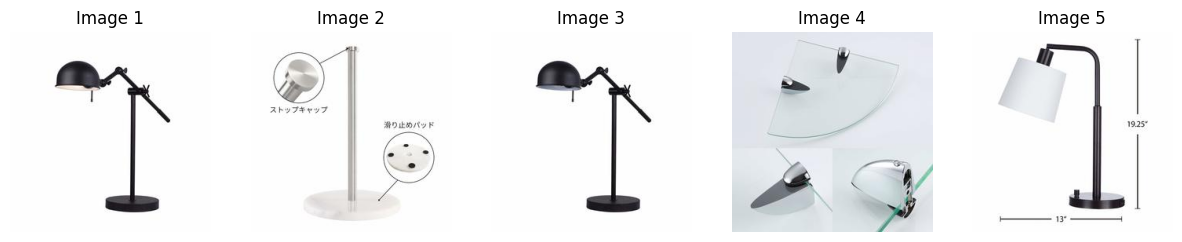

In [35]:
search("Desk lamp", k=5)